In [2]:
import polars as pl
import matplotlib.pyplot as plt
import contextily as ctx
import geopandas as gpd
from datetime import date

import yaml

with open("../config.budapest.yaml", "r") as fp:
    config = yaml.safe_load(fp)

In [3]:
device_ping_stats = pl.read_parquet(
    "/mnt/common-ssd/group-dirs/tkom-2026-project/pickwell/budapest/descriptives/device_stats.parquet"
)

In [4]:
PARTITION = 0  # between 0 and 255

In [5]:
stops = pl.read_parquet(
    f"{config['dirs']['output']}/{config['city']}/stops/{PARTITION:02x}.parquet"
)

In [6]:
stops.head(3)

device_id,stop_id,interval_start,interval_stop,interval_lenght,latitude_mean,longitude_mean,latitude_std,longitude_std,number_of_pings,place_label
i64,i32,"datetime[μs, Europe/Budapest]","datetime[μs, Europe/Budapest]",duration[μs],f64,f64,f64,f64,u32,i64
1,1,2024-10-02 07:24:06 CEST,2024-10-02 07:35:29 CEST,11m 23s,47.661166,19.076356,4.0,0.0,2,17
1,2,2024-10-05 11:06:43 CEST,2024-10-05 11:22:57 CEST,16m 14s,47.498402,19.0404,0.0,0.0,4,14
1,3,2024-10-05 17:49:22 CEST,2024-10-05 17:59:54 CEST,10m 32s,47.476742,19.075131,0.0,0.0,3,8


In [ ]:
stops.filter(pl.col.device_id == 4)

device_id,stop_id,interval_start,interval_stop,interval_lenght,latitude_mean,longitude_mean,latitude_std,longitude_std,number_of_pings,place_label
i64,i32,"datetime[μs, Europe/Budapest]","datetime[μs, Europe/Budapest]",duration[μs],f64,f64,f64,f64,u32,i64
4,1,2025-05-24 20:46:00 CEST,2025-05-24 21:01:21 CEST,15m 21s,47.821173,18.861989,7.0,9.0,30,3
4,2,2025-05-25 01:00:56 CEST,2025-05-25 01:34:01 CEST,33m 5s,47.500794,19.081097,2.0,9.0,8,1
4,3,2025-05-25 02:16:48 CEST,2025-05-25 10:20:06 CEST,8h 3m 18s,47.500836,19.081824,36.0,25.0,90,2
4,3,2025-05-25 02:16:48 CEST,2025-05-25 10:20:06 CEST,8h 3m 18s,47.500836,19.081824,36.0,25.0,90,1
4,4,2025-05-25 11:02:37 CEST,2025-05-25 11:14:56 CEST,12m 19s,47.500766,19.081774,14.0,11.0,8,1


# descriptives

In [5]:
# stops per user
stops_per_user = stops.group_by("device_id").agg(
    pl.col("stop_id").n_unique().alias("n_stops")
)
n_users_total = stops["device_id"].n_unique()
n_users_stopped = stops_per_user["device_id"].n_unique()

In [6]:
stops["interval_lenght"].describe()

statistic,value
str,str
"""count""","""401865"""
"""null_count""","""0"""
"""mean""","""1:45:54.778201"""
"""min""","""0:10:00"""
"""25%""","""0:11:18"""
"""50%""","""0:19:32"""
"""75%""","""0:46:46"""
"""max""","""426 days, 21:04:21"""


In [7]:
stops["interval_lenght"].quantile(0.90).total_seconds() / 3600

1.8933333333333333

In [8]:
stops["interval_lenght"].quantile(0.95).total_seconds() / 3600

3.303611111111111

In [9]:
stops["interval_lenght"].quantile(0.99).total_seconds() / 3600

9.506944444444445

In [10]:
stops["interval_lenght"].quantile(0.9936).total_seconds() / 3600

12.019444444444444

In [11]:
stops["interval_lenght"].quantile(0.997425).total_seconds() / 3600

23.967777777777776

In [12]:
stops["interval_lenght"].quantile(0.999).total_seconds() / 3600

75.45111111111112

In [13]:
24 * 3600


86400

In [24]:
stops.filter(pl.col("interval_lenght").dt.total_seconds() >= 86400).group_by(
    pl.col.device_id
).agg(pl.col.number_of_pings.sum())["number_of_pings"].describe()

statistic,value
str,f64
"""count""",437.0
"""null_count""",0.0
"""mean""",208.279176
"""std""",404.112199
"""min""",4.0
"""25%""",28.0
"""50%""",68.0
"""75%""",180.0
"""max""",3669.0


In [50]:
stops.filter(pl.col("interval_lenght").dt.total_seconds() >= 86400).group_by(
    [pl.col.device_id, pl.col.stop_id]
).agg(pl.col.number_of_pings.sum())

device_id,stop_id,number_of_pings
i64,i32,u32
45,44,49
154,22,94
2330,6,25
2334,4,37
2435,1,34
…,…,…
3973,32,385
4779,12,5
4852,556,137


In [ ]:
dd = (
    stops.filter(pl.col("interval_lenght").dt.total_seconds() >= 86400)
    .select(pl.col.device_id, pl.col.stop_id, pl.col.interval_lenght)
    .join(
        device_ping_stats.select(pl.col.device_id, pl.col.number_of_pings),
        on="device_id",
    )
)
dd.head(3)

device_id,stop_id,interval_lenght,number_of_pings
i64,i32,duration[μs],u32
1,26,2d 29m 24s,4466
12,290,1d 3h 54m 26s,25894
29,352,2d 13h 2m 14s,18854


In [47]:
dd.sort("number_of_pings")

device_id,stop_id,interval_lenght,number_of_pings
i64,i32,duration[μs],u32
4521,1,1d 48m 27s,14
4521,1,1d 48m 27s,14
4072,1,7d 13m 9s,18
1559,1,24d 16m 35s,30
1559,1,24d 16m 35s,30
…,…,…,…
1555,193,1d 6h 48m 43s,51613
1555,216,1d 10h 24m 29s,51613
1555,315,1d 4h 44m 58s,51613


In [ ]:
dd.with_columns(
    (pl.col.number_of_pings / pl.col.interval_lenght.dt.total_days()).alias(
        "pings_per_days"
    )
).sort("pings_per_days")

device_id,stop_id,interval_lenght,number_of_pings,pings_per_days
i64,i32,duration[μs],u32,f64
4122,5,214d 2h 55m 44s,81,0.378505
4122,5,214d 2h 55m 44s,81,0.378505
4109,6,426d 21h 4m 21s,257,0.603286
4109,6,426d 21h 4m 21s,257,0.603286
1721,3,113d 4h 22m 26s,84,0.743363
…,…,…,…,…
1555,76,1d 9h 32m 19s,51613,51613.0
1555,182,1d 4h 59m 42s,51613,51613.0
1555,193,1d 6h 48m 43s,51613,51613.0


In [75]:
stops.filter(pl.col("interval_lenght").dt.total_seconds() > 86400)[
    "interval_lenght"
].dt.total_hours().hist(bins=list(range(24, 9696, 24)))

breakpoint,category,count
f64,cat,u32
48.0,"""[24.0, 48.0]""",475
72.0,"""(48.0, 72.0]""",143
96.0,"""(72.0, 96.0]""",78
120.0,"""(96.0, 120.0]""",41
144.0,"""(120.0, 144.0]""",37
…,…,…
9576.0,"""(9552.0, 9576.0]""",0
9600.0,"""(9576.0, 9600.0]""",0
9624.0,"""(9600.0, 9624.0]""",0


In [ ]:
stops.filter(pl.col("interval_lenght").dt.total_seconds() > 86400)[
    "interval_lenght"
].dt.total_hours().hist(bins=list(range(24, 9696, 24))).filter(
    pl.col.count > 0
).to_pandas()

,breakpoint,category,count
0,48.0,"[24.0, 48.0]",475
1,72.0,"(48.0, 72.0]",143
2,96.0,"(72.0, 96.0]",78
3,120.0,"(96.0, 120.0]",41
4,144.0,"(120.0, 144.0]",37
...,...,...,...
57,6120.0,"(6096.0, 6120.0]",3
58,7200.0,"(7176.0, 7200.0]",4
59,7392.0,"(7368.0, 7392.0]",1
60,8664.0,"(8640.0, 8664.0]",2


<Axes: xlabel='category'>

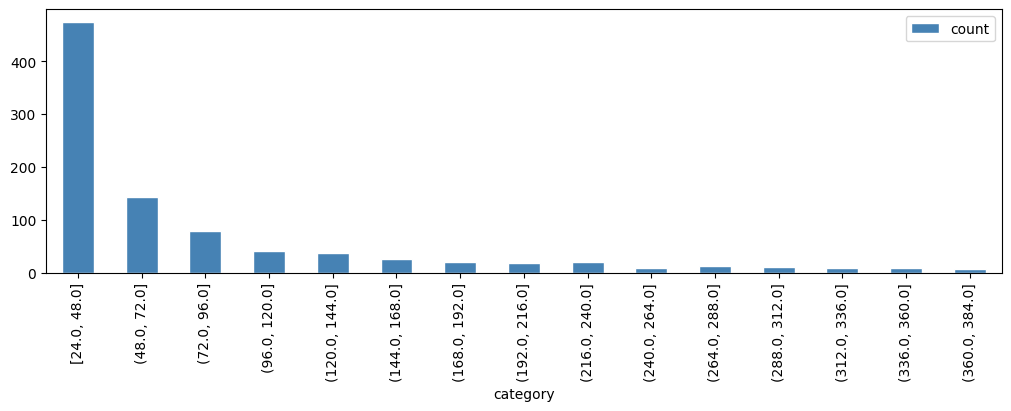

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
stops.filter(pl.col("interval_lenght").dt.total_seconds() > 86400)[
    "interval_lenght"
].dt.total_hours().hist(bins=list(range(24, 408, 24))).filter(
    pl.col.count > 0
).to_pandas().plot.bar(
    ax=ax, x="category", y="count", color="steelblue", edgecolor="white"
)

In [ ]:
stops

In [16]:
stops.filter(pl.col.interval_length.dt.seconds() < 86400)

AttributeError: 'ExprDateTimeNameSpace' object has no attribute 'seconds'

In [ ]:
stop_interval_distribution = stops.group_by("interval_lenght").agg(
    pl.col("stop_id").n_unique().alias("n_stops")
)

In [17]:
stops_per_user["n_stops"].clip(upper_bound=20).value_counts().sort(
    "count", descending=True
)

n_stops,count
u32,u32
20,2198
1,543
2,293
3,216
4,178
…,…
14,50
18,49
16,44


Users with >=1 stop:  4,478 / 4,478  (100.0%)

Stops per user:
shape: (9, 3)
┌────────────┬───────────┬─────────┐
│ statistic  ┆ device_id ┆ n_stops │
│ ---        ┆ ---       ┆ ---     │
│ str        ┆ i64       ┆ i64     │
╞════════════╪═══════════╪═════════╡
│ count      ┆ 4478      ┆ 4478    │
│ null_count ┆ 0         ┆ 0       │
│ mean       ┆ 3301      ┆ 88      │
│ std        ┆ 1907      ┆ 185     │
│ min        ┆ 1         ┆ 1       │
│ 25%        ┆ 1634      ┆ 4       │
│ 50%        ┆ 3314      ┆ 18      │
│ 75%        ┆ 4961      ┆ 80      │
│ max        ┆ 6584      ┆ 4002    │
└────────────┴───────────┴─────────┘


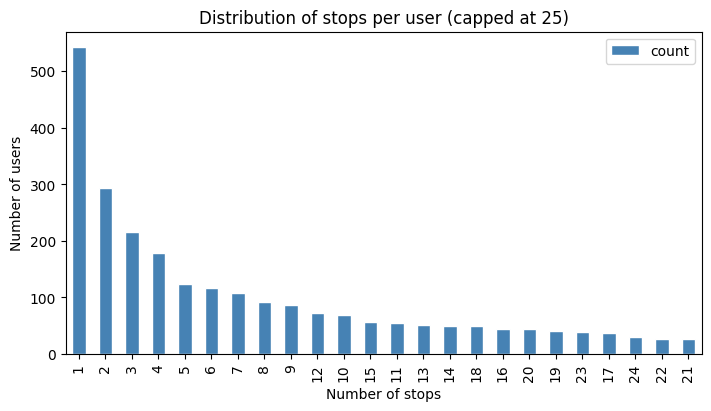

In [18]:
print(
    f"Users with >=1 stop:  {n_users_stopped:,} / {n_users_total:,}  ({n_users_stopped / n_users_total:.1%})"
)
print("\nStops per user:")
print(
    stops_per_user.describe().with_columns(
        pl.col.device_id.round().cast(pl.Int64),
        pl.col.n_stops.round().cast(pl.Int64),
    )
)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
# stops_per_user["n_stops"].clip(upper_bound=20).value_counts().sort(
#     "count", descending=True
# ).to_pandas().plot.bar(
#     ax=ax, x="n_stops", y="count", color="steelblue", edgecolor="white"
# )
stops_per_user.filter(pl.col.n_stops < 25)["n_stops"].value_counts().sort(
    "count", descending=True
).to_pandas().plot.bar(
    ax=ax, x="n_stops", y="count", color="steelblue", edgecolor="white"
)
ax.set_xlabel("Number of stops")
ax.set_ylabel("Number of users")
_ = ax.set_title("Distribution of stops per user (capped at 25)")

works on clustered pings

In [ ]:
example_device = 40  # old 16
# example_device = 290  # old 133

user_df = stops.filter(
    (pl.col.device_id == example_device)
    & (pl.col.timestamp.dt.date() == date(2025, 10, 6))
)

# build GeoDataFrame in Web Mercator for contextily
gdf = gpd.GeoDataFrame(
    user_df.to_pandas(),
    geometry=gpd.points_from_xy(user_df["longitude"], user_df["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:3857")

fig, ax = plt.subplots(figsize=(12, 12), layout="constrained")

# moving pings
gdf[gdf["stop_id"] < 0].plot(
    ax=ax, color="grey", markersize=4, alpha=0.5, label="moving"
)

# stop pings — colour by stop cluster
stop_gdf = gdf[gdf["stop_id"] >= 0]
stop_gdf.plot(
    ax=ax,
    column="stop_id",
    cmap="tab10",
    markersize=30,
    alpha=0.85,
    legend=False,
    label="stop",
)

# annotate stop cluster centres
for label, grp in stop_gdf.groupby("stop_id"):
    cx, cy = grp.geometry.x.mean(), grp.geometry.y.mean()
    ax.annotate(
        str(label), (cx, cy), fontsize=7, ha="center", color="black", fontweight="bold"
    )

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, zoom="auto")

ax.set_axis_off()
_ = ax.set_title(f"Device {example_device} — all pings + stop clusters", pad=12)